# **RQ2: Coastal Exposure, Drifter Movement and Short-Term Forecasting**

**Figures in this notebook for the Final Report:**

2.1 Distance of warm-condition GDP drifters from the mapped coastline during the two marine heatwaves.

2.2 Distribution of drifter-level median distances to the coastline.

2.3 Observed and predicted 24-hour GDP drifter movements under Models A, B and C.

2.4 Table: 24-hour coastal endpoint classification performance by model and marine heatwave event

2.5 (Temperature persistence) Warm-class F1 scores for the temperature-persistence baseline at forecast horizons of 24, 48 and 72 hours during the 2013–2016 Blob and the 2019–2020 marine heatwave.


## 1. Setup and Process Existing Project Inputs

In [2]:
from pathlib import Path
import io, zipfile
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import requests
import geopandas as gpd
import shapely
from shapely.geometry import box
from shapely.strtree import STRtree
from pyproj import CRS, Transformer, Geod
from sklearn.metrics import precision_score, recall_score, f1_score
from IPython.display import display

DATA = Path('../data/processed')
GDP_FILE = DATA / 'california_current_new.zarr'
CLIM_FILE = DATA / 'oisst_climatology_1982_2011.nc'
REF_FILE = DATA / 'oisst_mhw_reference_2013_2020.nc'
OISST_FOLDER = DATA / 'oisst_yearly'
OUT = Path('../figures/rq2')
OUT.mkdir(parents=True, exist_ok=True)
EVENTS = ['2013–2016 Blob', '2019–2020 MHW']
EVENT_YEARS = [2013, 2014, 2015, 2016, 2019, 2020]
REGION = (-135., -115., 25., 48.)
COASTAL_KM = 50.

for path in [GDP_FILE, CLIM_FILE, REF_FILE]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}; run earlier notebooks first.')

cc = xr.open_zarr(GDP_FILE)
climatology = xr.open_dataset(CLIM_FILE)
reference_ds = xr.open_dataset(REF_FILE)
assert '1982' in CLIM_FILE.name and '2011' in CLIM_FILE.name
assert {'p90_sst', 'mean_sst'}.issubset(climatology.data_vars)
assert 'mhw_reference' in reference_ds

## 2. Match daily OISST reference and GDP observations
Use the saved OISST five-day reference from Notebook 04, rather than recalculating it using another baseline. Load the same event-year OISST files for the SST anomaly map and preserve a separate GDP trajectory identifier.

In [3]:
# read the same yearly event files produced in Notebook 03.
event_arrays = []
for year in EVENT_YEARS:
    path = OISST_FOLDER / f'oisst_cc_{year}.nc'
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}; run Notebook 03.')
    with xr.open_dataset(path) as ds:
        event_arrays.append(ds['sst'].load())
oisst_events = xr.concat(event_arrays, dim='time').sortby('time')

# calendar-day mapping follows Notebook 04: Feb 29 uses Feb 28 threshold.
dates = pd.DatetimeIndex(oisst_events.time.values)
month_day = np.where(dates.strftime('%m-%d') == '02-29', '02-28', dates.strftime('%m-%d'))
season_day = pd.to_datetime('2001-' + month_day).dayofyear
day_index = xr.DataArray(season_day, dims='time', coords={'time': oisst_events.time})
daily_mean = climatology['mean_sst'].sel(dayofyear=day_index)

# use exact same OISST MHW mask generated in Notebook 04.
reference = reference_ds['mhw_reference']
assert np.array_equal(reference.time.values, oisst_events.time.values), 'OISST/reference dates differ'
oisst_anom = oisst_events - daily_mean

# retain the full hourly GDP positions for trajectory matching.
ids = np.repeat(cc['id'].values, cc['rowsize'].values.astype('int64'))
if len(ids) != cc.sizes['obs']:
    raise ValueError('GDP trajectory IDs do not match observation dimension')
positions = pd.DataFrame({
    'traj_id': ids,
    'time': pd.to_datetime(cc['time'].values, utc=True).tz_convert(None),
    'lat': cc['lat'].values,
    'lon': cc['lon'].values,
    'flg_sst': cc['flg_sst'].values,
    'sst': cc['sst'].values,
})
positions = positions.dropna(subset=['traj_id','time','lat','lon'])
positions = positions.loc[
    positions.lat.between(REGION[2], REGION[3]) &
    positions.lon.between(REGION[0], REGION[1])
].copy()
positions['event'] = np.select([
    positions.time.dt.year.between(2013, 2016),
    positions.time.dt.year.between(2019, 2020)
], EVENTS, default='Other')
positions = positions.loc[positions.event.isin(EVENTS)]
positions = positions.drop_duplicates(['traj_id','time']).sort_values(['traj_id','time'])
obs = positions.loc[(positions.flg_sst == 5) & positions.sst.notna()].copy()

def closest_index(grid, values):
    grid = np.asarray(grid)
    values = np.asarray(values)
    right = np.searchsorted(grid, values)
    lo = np.clip(right-1, 0, len(grid)-1)
    hi = np.clip(right, 0, len(grid)-1)
    return np.where(np.abs(grid[lo]-values) <= np.abs(grid[hi]-values), lo, hi)

# match by calendar date and nearest OISST cell. Dates in 2017–18 are absent.
ref_dates = pd.DatetimeIndex(reference.time.values).normalize()
obs_dates = pd.DatetimeIndex(obs.time).normalize()
t_index = ref_dates.get_indexer(obs_dates)
lat_index = closest_index(reference.lat.values, obs.lat.to_numpy())
lon_index = closest_index(reference.lon.values, np.mod(obs.lon.to_numpy(), 360))
valid = (t_index >= 0)
flags = np.zeros(len(obs), dtype=bool)
anomalies = np.full(len(obs), np.nan)
k = np.flatnonzero(valid)
flags[k] = reference.values[t_index[k], lat_index[k], lon_index[k]]
anomalies[k] = oisst_anom.values[t_index[k], lat_index[k], lon_index[k]]
obs['in_mhw'] = flags
obs['oisst_anomaly_c'] = anomalies
warm = obs.loc[obs.in_mhw & obs.oisst_anomaly_c.notna()].copy()
if warm.empty:
    raise ValueError('No GDP observations match qualifying OISST marine heatwaves')
display(warm.groupby('event').agg(observations=('time','size'), drifters=('traj_id','nunique')).reindex(EVENTS))

,observations,drifters
event,,
2013–2016 Blob,247416,85
2019–2020 MHW,98210,71


## 3. Coastline distance (50 km rule)
The coastline geometry, projection and distance calculation follow the teammate’s original notebook.

In [4]:
# load the coastline and calculate shoreline distance =====
coast_folder = DATA / 'coastline'
coast_folder.mkdir(parents=True,exist_ok=True)
coast_shp = coast_folder/'ne_10m_coastline.shp'
if not coast_shp.exists():
    url='https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip'
    # Download coastline if not cached
    r=requests.get(url,timeout=180)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as archive:
        archive.extractall(coast_folder)

coast = gpd.read_file(coast_shp,bbox=(-140,22,-110,51)).to_crs('EPSG:4326')
coast['geometry'] = coast.geometry.intersection(box(-140,22,-110,51))
coast = coast.loc[~coast.geometry.is_empty & coast.geometry.notna()].copy()
if coast.empty:
    raise ValueError('No coastline features found for California Current region')

# metric map projection centred on the study region (approximate km distances).
LOCAL_CRS = CRS.from_proj4('+proj=aeqd +lat_0=37 +lon_0=-125 +datum=WGS84 +units=m +no_defs')
coast_metric = coast.to_crs(LOCAL_CRS)
tree = STRtree(list(coast_metric.geometry))
transform = Transformer.from_crs('EPSG:4326',LOCAL_CRS,always_xy=True)

def distance_to_coast_km(lon,lat,batch_size=20000):
    lon=np.asarray(lon,dtype=float)
    lat=np.asarray(lat,dtype=float)
    result=np.full(len(lon),np.nan)
    good=np.flatnonzero(np.isfinite(lon)&np.isfinite(lat))
    for start in range(0,len(good),batch_size):
        indices=good[start:start+batch_size]
        x,y=transform.transform(lon[indices],lat[indices])
        points=shapely.points(x,y)
        nearest,distance_metres=tree.query_nearest(points,return_distance=True,all_matches=False)
        result[indices[nearest[0]]] = distance_metres/1000
    return result

warm['coast_km'] = distance_to_coast_km(warm.lon,warm.lat)
warm['near_coast'] = warm.coast_km <= COASTAL_KM

## 4. Figure 2.1: Distance of warm-condition GDP drifters from the mapped coastline

In [6]:
# match actual drifter positions 24 hours apart
future = positions[['traj_id','time','event','lat','lon']].rename(
    columns={'lat':'lat_future','lon':'lon_future'}).copy()
future['time'] = future['time'] - pd.Timedelta(hours=24)
pairs = warm.merge(future,on=['traj_id','time','event'],how='inner',validate='one_to_one')

def haversine_km(lat1,lon1,lat2,lon2):
    p1,p2=np.radians(lat1),np.radians(lat2)
    dp=np.radians(lat2-lat1)
    dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))

pairs['displacement_km'] = haversine_km(
    pairs.lat.values,pairs.lon.values,pairs.lat_future.values,pairs.lon_future.values)
pairs['coast_future_km'] = distance_to_coast_km(pairs.lon_future,pairs.lat_future)
pairs['delta_coast_km'] = pairs.coast_future_km - pairs.coast_km

In [8]:
# Define offshore_steps for Figure 2.1
# Uses the existing warm observations and all GDP positions

# Get positions observed one hour later
next_hour = positions[
    ["traj_id", "time", "event", "lat", "lon"]
].rename(
    columns={
        "lat": "next_lat",
        "lon": "next_lon"
    }
).copy()

# Shift timestamps back one hour so they match starting observations
next_hour["time"] = next_hour["time"] - pd.Timedelta(hours=1)

# Match warm starting positions to actual next-hour observations
hour_pairs = warm.merge(
    next_hour,
    on=["traj_id", "time", "event"],
    validate="one_to_one"
)

# Calculate distance from coast at the next observation
hour_pairs["next_coast_km"] = distance_to_coast_km(
    hour_pairs["next_lon"],
    hour_pairs["next_lat"]
)

# Only include starting positions offshore
offshore_steps = hour_pairs.loc[
    (hour_pairs["coast_km"] > COASTAL_KM)
    & hour_pairs["next_coast_km"].notna()
].copy()

# Identify crossings into the coastal zone
offshore_steps["entry"] = (
    offshore_steps["next_coast_km"] <= COASTAL_KM
)

# Verify
print("Offshore steps created:", len(offshore_steps))
print("Observed coastal entries:", int(offshore_steps["entry"].sum()))
print("Columns:", offshore_steps.columns.tolist())


Offshore steps created: 340508
Observed coastal entries: 31
Columns: ['traj_id', 'time', 'lat', 'lon', 'flg_sst', 'sst', 'event', 'in_mhw', 'oisst_anomaly_c', 'coast_km', 'near_coast', 'next_lat', 'next_lon', 'next_coast_km', 'entry']


In [9]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from IPython.display import display

NEEDED = ["warm", "pairs", "offshore_steps", "coast", "coast_metric",
          "LOCAL_CRS", "COASTAL_KM", "EVENTS"]
missing = [x for x in NEEDED if x not in globals()]
if missing:
    raise NameError("Run earlier Part A cells first; missing: " + ", ".join(missing))
for name, cols in {
    "warm": ["event", "traj_id", "time", "lat", "lon", "coast_km", "near_coast", "oisst_anomaly_c"],
    "pairs": ["event", "traj_id", "displacement_km", "delta_coast_km"],
    "offshore_steps": ["event", "traj_id", "entry", "lon", "lat", "next_lon", "next_lat"],
}.items():
    absent = [c for c in cols if c not in globals()[name].columns]
    if absent:
        raise KeyError(f"{name} missing {absent}: run the corresponding Part A calculation")

SAVE_TO = OUT
SAVE_TO.mkdir(parents=True, exist_ok=True)
REGION_BOX = (-135, -115, 25, 48)
HOT = LinearSegmentedColormap.from_list(
    "white_yellow_orange_red",
    ["#FDFBF7", "#FFF0C2", "#FFDC70", "#F6A34A", "#E45A2C", "#A71D26"],
    N=256)
COASTLINE = "#394A55"
BORDER = "#C48721"

# Uses the same coastline geometry/projection/50 km definition as your Part A calculations.
coastal_zone_ll = gpd.GeoSeries(
    [coast_metric.geometry.union_all().buffer(COASTAL_KM * 1000)],
    crs=LOCAL_CRS
).to_crs("EPSG:4326")

def map_base(ax, event):
    coast.plot(ax=ax, linewidth=0.65, color=COASTLINE, zorder=7)
    coastal_zone_ll.boundary.plot(ax=ax, color=BORDER, linewidth=0.9,
                                  linestyle="--", zorder=8)
    ax.set_xlim(*REGION_BOX[:2]); ax.set_ylim(*REGION_BOX[2:])
    ax.set_aspect(1 / np.cos(np.deg2rad(36)))
    ax.grid(alpha=.13, linewidth=.4)
    ax.set_title(event, fontsize=12, weight="bold")
    ax.set_xlabel("Longitude (°)")


def annotation(ax, txt):
    ax.text(.025, .025, txt, transform=ax.transAxes, fontsize=9,
            va="bottom", bbox={"boxstyle":"round,pad=.36", "facecolor":"white",
                               "alpha":.91, "edgecolor":"none"}, zorder=20)


def choose_points(df, max_per_drifter=45):
    # uniform random sample per drifter for display only, never for numerical estimates.
    if df.empty:
        return df.copy()
    return pd.concat([
        g.sample(n=min(max_per_drifter, len(g)), random_state=42)
        for _, g in df.groupby("traj_id", sort=False)
    ], ignore_index=True)

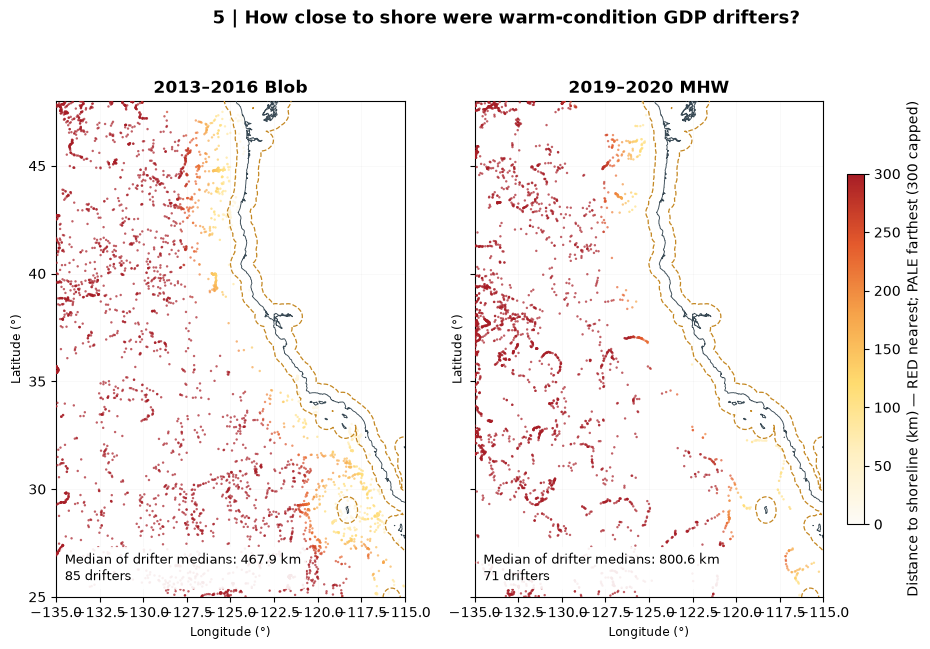

In [10]:
# Figure 2.1: Distance of warm-condition GDP drifters from coastline

fig, axes = plt.subplots(
    1, 2, figsize=(12, 7), sharex=True, sharey=True
)

event_titles = {
    "2013–2016 Blob": "2013–2016 Blob",
    "2019–2020 MHW": "2019–2020 MHW"
}

# Use the event labels already defined in this notebook
for ax, event in zip(axes, EVENTS):
    subset = warm.loc[
        (warm["event"] == event)
        & warm["lat"].notna()
        & warm["lon"].notna()
        & warm["coast_km"].notna()
    ].copy()

    # Sample only for visual clarity, not for summary statistics
    display_points = choose_points(subset, max_per_drifter=45)

    ax.scatter(
        display_points["lon"],
        display_points["lat"],
        c=display_points["coast_km"].clip(0, 300),
        cmap=HOT,
        norm=Normalize(vmin=0, vmax=300),
        s=3,
        alpha=0.7,
        linewidths=0,
        rasterized=True,
        zorder=3
    )

    map_base(ax, event)

    # Calculate each drifter's median coastal distance,
    # then take the median across drifters
    drifter_medians = (
        subset.groupby("traj_id")["coast_km"].median()
    )

    median_km = drifter_medians.median()
    n_drifters = drifter_medians.size

    annotation(
        ax,
        f"Median of drifter medians: {median_km:.1f} km\n"
        f"{n_drifters} drifters"
    )

    ax.set_ylabel("Latitude (°)")

# Shared colour bar
sm = ScalarMappable(
    norm=Normalize(vmin=0, vmax=300),
    cmap=HOT
)
sm.set_array([])

cbar = fig.colorbar(
    sm, ax=axes, shrink=0.65, pad=0.025
)
cbar.set_label(
    "Distance to shoreline (km) — RED nearest; PALE farthest (300 capped)"
)

fig.suptitle(
    "5 | How close to shore were warm-condition GDP drifters?",
    fontsize=13,
    weight="bold",
    y=0.98
)

fig.savefig(
    SAVE_TO / "Figure_2_1_coastline_distance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()


## 5. Figure 2.2: Drifter-level median distance to the coastline

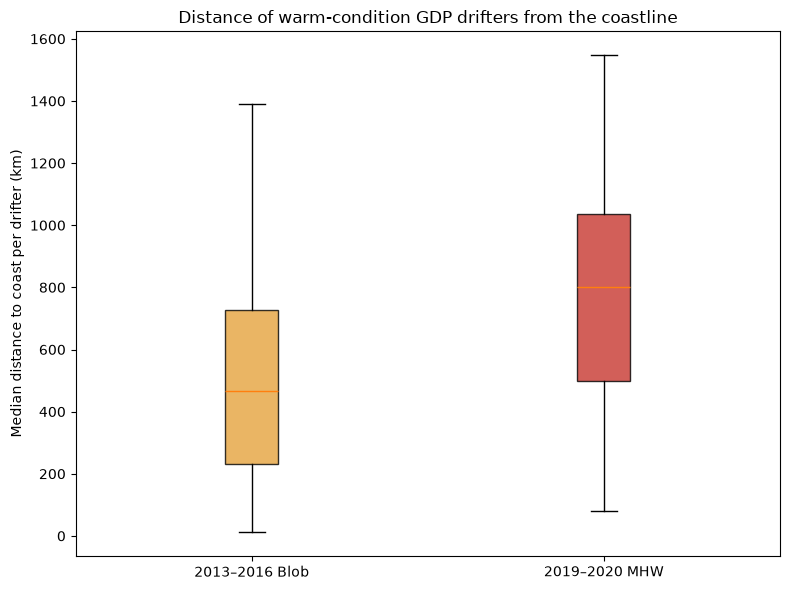

,count,median,mean,std,min,max
event,,,,,,
2013–2016 Blob,85,467.95,496.94,326.05,12.24,1562.33
2019–2020 MHW,71,800.57,770.52,351.40,78.73,1547.41


In [11]:
# median distance to coast per drifter
distance_by_drifter = (
    warm.groupby(['event', 'traj_id'], as_index=False)['coast_km']
    .median()
)

# boxplot
fig, ax = plt.subplots(figsize=(8, 6))

data_to_plot = [
    distance_by_drifter.loc[
        distance_by_drifter['event'] == evt, 'coast_km'
    ].dropna()
    for evt in EVENTS
]

box = ax.boxplot(
    data_to_plot,
    tick_labels=EVENTS,
    patch_artist=True,
    showfliers=False
)


# optional colours
colors = ['#e5a33d', '#c7372f']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.set_ylabel("Median distance to coast per drifter (km)")
ax.set_title("Distance of warm-condition GDP drifters from the coastline")

plt.tight_layout()
plt.savefig(OUT / 'Figure_2_2_drifter_median_distance.png', dpi=300, bbox_inches='tight')
plt.show()

# summary table
summary = (
    distance_by_drifter.groupby('event')['coast_km']
    .agg(['count', 'median', 'mean', 'std', 'min', 'max'])
    .round(2)
)

display(summary)

## 6. Observed 24-hour positions and velocity histories

In [12]:
# IMPORTANT: Do NOT read ve/vn from obs: 
# (part A's obs does not contain those columns)
# build velocities from the original GDP observation dimension 
# (correctly aligned with id/rowsize).
for name in ['ve', 'vn', 'id', 'rowsize', 'time']:
    if name not in cc:
        raise KeyError(f'Missing GDP variable in cc: {name}')
    if name in ['ve', 'vn']:
        pass

# the GDP files used for this project have velocities in m/s.
for name in ['ve', 'vn']:
    units = str(cc[name].attrs.get('units', '')).lower().replace(' ', '')
    if units and units not in ('m/s', 'ms-1', 'm.s-1', 'metersecond-1', 'meterspersecond'):
        raise ValueError(f'{name} units appear to be {cc[name].attrs.get("units")}. Verify/convert to m/s first.')

ids = np.repeat(cc['id'].values, cc['rowsize'].values.astype(np.int64))
if len(ids) != cc.sizes['obs']:
    raise ValueError('GDP id and rowsize do not agree with obs dimension.')

vel = pd.DataFrame({
    'traj_id': ids,
    'time': pd.to_datetime(cc['time'].values, utc=True).tz_convert(None),
    've': cc['ve'].values.astype('float64'),
    'vn': cc['vn'].values.astype('float64'),
})
vel = vel.sort_values(['traj_id', 'time']).drop_duplicates(['traj_id', 'time'])

# model C: mean of *past* six hours (t-6h to t-1h), only when all six are hourly.
for field in ['ve', 'vn']:
    vel[field + '_past6'] = (
        vel.groupby('traj_id', sort=False)[field]
           .transform(lambda s: s.shift(1).rolling(6, min_periods=6).mean())
    )
g = vel.groupby('traj_id', sort=False)
consecutive = (
    (vel['time'] - g['time'].shift(1) == pd.Timedelta(hours=1)) &
    (vel['time'] - g['time'].shift(6) == pd.Timedelta(hours=6))
)
vel.loc[~consecutive, ['ve_past6', 'vn_past6']] = np.nan

starts = pairs.copy()
starts['time'] = pd.to_datetime(starts['time'], utc=True).dt.tz_localize(None)
required = ['event', 'traj_id', 'time', 'lon', 'lat', 'lon_future', 'lat_future', 'coast_km', 'coast_future_km']
if any(x not in starts.columns for x in required):
    raise KeyError(f'Part A pairs is missing: {[x for x in required if x not in starts.columns]}')

# keep only pairs with a recorded real +24h endpoint and valid velocity data for ALL models.
starts = starts.merge(
    vel[['traj_id', 'time', 've', 'vn', 've_past6', 'vn_past6']],
    on=['traj_id', 'time'], how='left', validate='one_to_one'
)
starts = starts.loc[np.isfinite(starts[
    ['ve', 'vn', 've_past6', 'vn_past6', 'lon', 'lat', 'lon_future', 'lat_future', 'coast_future_km']
].to_numpy(dtype=float)).all(axis=1)].copy().reset_index(drop=True)

if starts.empty:
    raise ValueError('No common starts with real 24h positions and six consecutive prior hours of velocity.')

## 7. Figure 2.3 — Observed and predicted 24-hour drifter movements
Model A: stationary

Model B: current east/north velocity 

Model C: mean of six preceding hourly velocities. All models use identical valid starting positions.

In [13]:
# predict the 24-hour positions with Models A, B and C
geod = Geod(ellps='WGS84')
SECONDS = 24 * 3600

def endpoint(lon, lat, ve_mps, vn_mps):
    # bearing clockwise from true north; distance = speed * elapsed seconds.
    azimuth = np.degrees(np.arctan2(ve_mps, vn_mps))
    distance_m = np.hypot(ve_mps, vn_mps) * SECONDS
    end_lon, end_lat, _ = geod.fwd(
        np.asarray(lon), np.asarray(lat), azimuth, distance_m
    )
    return end_lon, end_lat

# A: no movement
starts['pred_A_lon'] = starts['lon'].to_numpy(dtype=float)
starts['pred_A_lat'] = starts['lat'].to_numpy(dtype=float)

# B: latest velocity at start
starts['pred_B_lon'], starts['pred_B_lat'] = endpoint(
    starts.lon, starts.lat, starts.ve, starts.vn
)

# C: mean of six *prior* hourly velocities
starts['pred_C_lon'], starts['pred_C_lat'] = endpoint(
    starts.lon, starts.lat, starts.ve_past6, starts.vn_past6
)

for m in 'ABC':
    _, _, error_metres = geod.inv(
        starts[f'pred_{m}_lon'].to_numpy(), starts[f'pred_{m}_lat'].to_numpy(),
        starts.lon_future.to_numpy(), starts.lat_future.to_numpy()
    )
    starts[f'err_{m}_km'] = error_metres / 1000
    starts[f'coast_{m}_km'] = distance_to_coast_km(
        starts[f'pred_{m}_lon'].to_numpy(), starts[f'pred_{m}_lat'].to_numpy()
    )
    starts[f'coastal_{m}'] = starts[f'coast_{m}_km'] <= COASTAL_KM

starts['actual_coastal'] = starts.coast_future_km <= COASTAL_KM

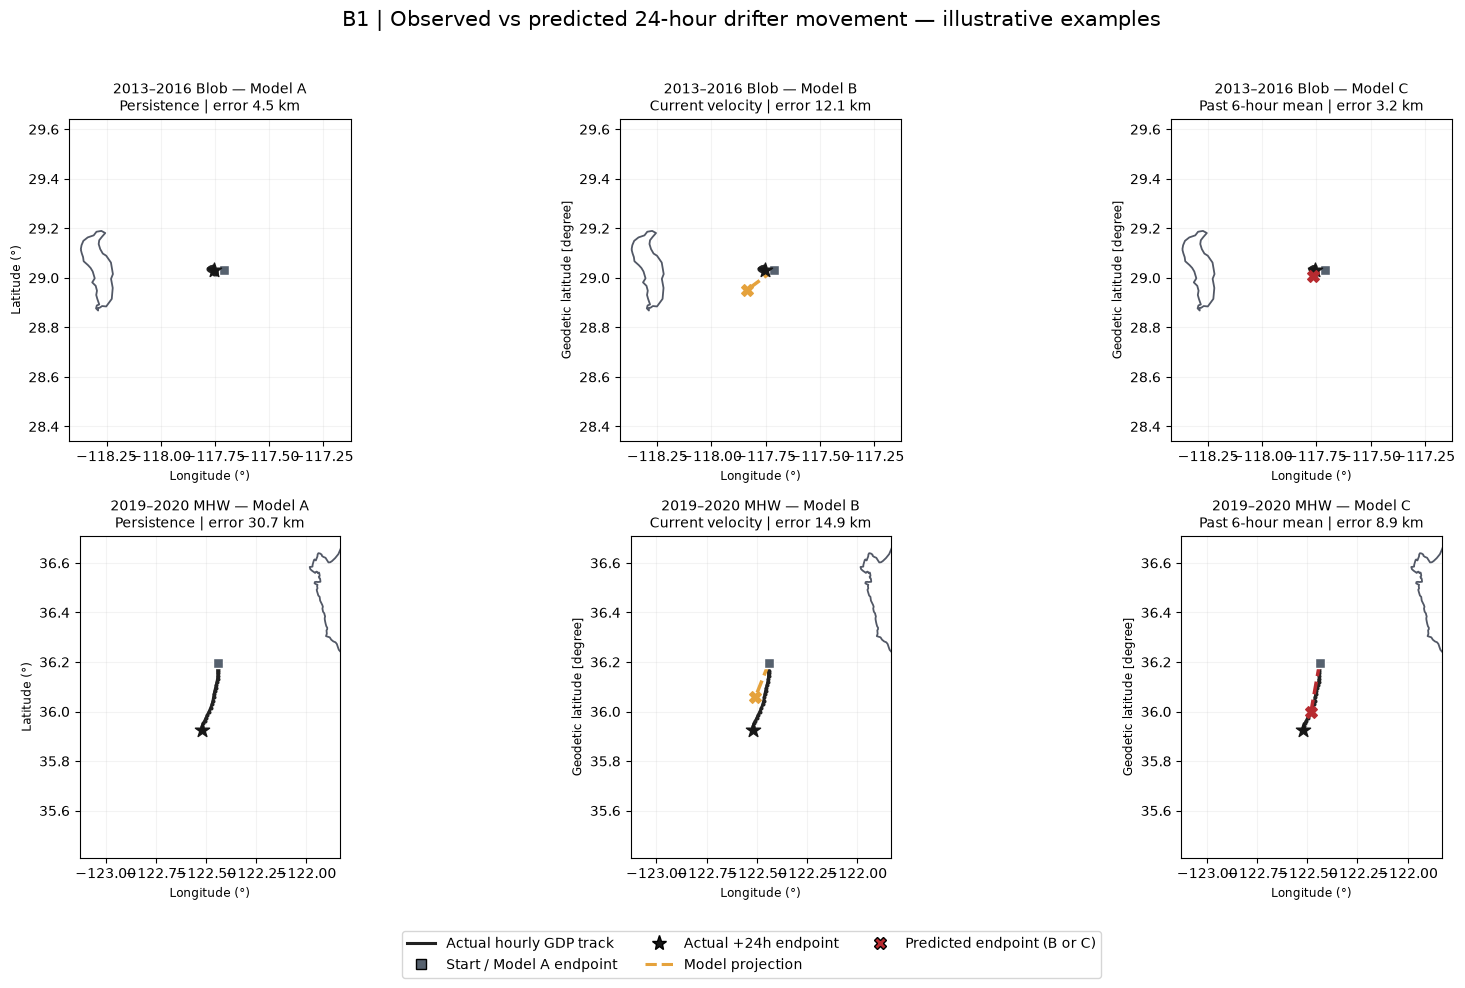

In [14]:
# plot observed vs predicted 24-hour tracks
from shapely.geometry import box

model_names = {'A': 'Persistence', 'B': 'Current velocity', 'C': 'Past 6-hour mean'}
model_colors = {'A': '#9A9A9A', 'B': '#E5A23C', 'C': '#B72B30'}
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=False, sharey=False)

for i, event in enumerate(EVENTS):
    subset = starts.loc[starts.event == event].copy()
    if subset.empty:
        continue
    # choose a representative start closest to the 50-km boundary, with a non-tiny actual displacement.
    plausible = subset[(subset.err_B_km <= subset.err_B_km.quantile(.95))].copy()
    plausible['distance_from_boundary_km'] = (plausible.coast_km - COASTAL_KM).abs()
    choice = plausible.sort_values('distance_from_boundary_km').iloc[0]

    t0 = pd.Timestamp(choice.time)
    actual_track = positions.loc[
        (positions.traj_id == choice.traj_id) &
        (positions.time >= t0) &
        (positions.time <= t0 + pd.Timedelta(hours=24))
    ].sort_values('time')

    all_lon = [choice.lon, choice.lon_future, choice.pred_B_lon, choice.pred_C_lon]
    all_lat = [choice.lat, choice.lat_future, choice.pred_B_lat, choice.pred_C_lat]
    lon_middle = (min(all_lon) + max(all_lon)) / 2
    lat_middle = (min(all_lat) + max(all_lat)) / 2
    padx = max(.65, (max(all_lon) - min(all_lon)) * 1.2)
    pady = max(.65, (max(all_lat) - min(all_lat)) * 1.2)
    view = box(lon_middle - padx, lat_middle - pady, lon_middle + padx, lat_middle + pady)
    local_lines = coast.loc[coast.geometry.intersects(view)]

    for j, m in enumerate('ABC'):
        ax = axes[i, j]
        if not local_lines.empty:
            local_lines.plot(ax=ax, color='#525866', linewidth=1.3)
        ax.plot(actual_track.lon, actual_track.lat, color='#222222', lw=2.1, marker='o',
                markersize=1.9, zorder=4)
        ax.plot([choice.lon, choice[f'pred_{m}_lon']],
                [choice.lat, choice[f'pred_{m}_lat']], '--',
                color=model_colors[m], lw=2.5, zorder=5)
        ax.scatter(choice.lon, choice.lat, s=60, marker='s', color='#56616E',
                   edgecolors='white', zorder=7)
        ax.scatter(choice.lon_future, choice.lat_future, s=115, marker='*',
                   color='#171717', zorder=8)
        if m != 'A':
            ax.scatter(choice[f'pred_{m}_lon'], choice[f'pred_{m}_lat'],
                       color=model_colors[m], marker='X', s=70, zorder=8)
        ax.set_xlim(lon_middle - padx, lon_middle + padx)
        ax.set_ylim(lat_middle - pady, lat_middle + pady)
        ax.set_aspect(1 / np.cos(np.deg2rad(lat_middle)))
        ax.grid(alpha=.15)
        ax.set_title(f'{event} — Model {m}' + chr(10) + f'{model_names[m]} | error {choice[f"err_{m}_km"]:.1f} km', fontsize=10)
        ax.set_xlabel('Longitude (°)')
        if j == 0:
            ax.set_ylabel('Latitude (°)')

legend = [
    Line2D([0], [0], color='#222222', lw=2.2, label='Actual hourly GDP track'),
    Line2D([0], [0], marker='s', color='none', markerfacecolor='#56616E',
           markersize=7, label='Start / Model A endpoint'),
    Line2D([0], [0], marker='*', color='none', markerfacecolor='#171717',
           markersize=11, label='Actual +24h endpoint'),
    Line2D([0], [0], linestyle='--', color='#E5A23C', lw=2.2, label='Model projection'),
    Line2D([0], [0], marker='X', color='none', markerfacecolor='#B72B30',
           markersize=8, label='Predicted endpoint (B or C)'),
]
fig.legend(handles=legend, loc='lower center', ncol=3, bbox_to_anchor=(.5, .005))
fig.suptitle('B1 | Observed vs predicted 24-hour drifter movement — illustrative examples', fontsize=15)
fig.tight_layout(rect=[0, .075, 1, .96])
fig.savefig(OUT / 'Figure_2_3_observed_predicted_24h.png', dpi=220, bbox_inches='tight')
plt.show()

## 8. Figure 2.4: Coastal endpoint classification performance table
Compare predicted versus observed endpoints within 50 km of the coastline, separately by event. Precision, recall and F1 use the coastal class as positive.

In [15]:
table_rows = []
for event in EVENTS:
    sample = starts.loc[starts.event == event]
    for model in 'ABC':
        truth = sample['actual_coastal'].astype(bool)
        pred = sample[f'coastal_{model}'].astype(bool)
        tp = int((truth & pred).sum())
        fp = int((~truth & pred).sum())
        fn = int((truth & ~pred).sum())
        tn = int((~truth & ~pred).sum())
        table_rows.append({
            'Event': event, 'Model': model, 'N': len(sample),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Precision': precision_score(truth, pred, zero_division=0),
            'Recall': recall_score(truth, pred, zero_division=0),
            'F1': f1_score(truth, pred, zero_division=0),
            'Median endpoint error (km)': sample[f'err_{model}_km'].median()
        })
coastal_endpoint_table = pd.DataFrame(table_rows)
display(coastal_endpoint_table.round(3))
coastal_endpoint_table.to_csv(OUT / 'Table_2_4_coastal_endpoint_performance.csv', index=False)

,Event,Model,N,TP,FP,FN,TN,Precision,Recall,F1,Median endpoint error (km)
0,2013–2016 Blob,A,242595,4114,327,548,237606,0.926,0.882,0.904,9.381
1,2013–2016 Blob,B,242595,4279,442,383,237491,0.906,0.918,0.912,9.220
2,2013–2016 Blob,C,242595,4314,415,348,237518,0.912,0.925,0.919,8.018
3,2019–2020 MHW,A,94303,10,51,51,94191,0.164,0.164,0.164,9.758
4,2019–2020 MHW,B,94303,37,98,24,94144,0.274,0.607,0.378,10.516
5,2019–2020 MHW,C,94303,46,102,15,94140,0.311,0.754,0.440,9.529


## 9. Figure 2.5: Warm-class temperature persistence at 24, 48 and 72 hours
Use Model B’s GDP SST > local historical P90 classification from the same 1982–2011 climatology. A persistence forecast copies the starting class forward; evaluate against a later observation from the same drifter.

In [16]:
# reuse obs (valid GDP SST, drifter IDs, and event labels) and climatology
temp_data = obs[['event','traj_id','time','lat','lon','sst']].copy()
temp_data['sst_c'] = temp_data['sst'].astype(float) - 273.15
_temp_dates = pd.DatetimeIndex(temp_data.time)
_temp_monthday = np.where(_temp_dates.strftime('%m-%d') == '02-29', '02-28',
                          _temp_dates.strftime('%m-%d'))
_temp_day = pd.to_datetime('2001-' + _temp_monthday).dayofyear.to_numpy()
p90 = climatology['p90_sst']
_p90_lat = closest_index(p90.lat.values, temp_data.lat.to_numpy())
_p90_lon = closest_index(p90.lon.values, np.mod(temp_data.lon.to_numpy(),360))
temp_data['p90_c'] = p90.values[_temp_day-1, _p90_lat, _p90_lon]
temp_data = (temp_data[['event','traj_id','time','sst_c','p90_c']]
             .dropna().sort_values(['event','traj_id','time'])
             .drop_duplicates(['event','traj_id','time']))
temp_data['warm_now'] = temp_data['sst_c'] > temp_data['p90_c']

In [17]:
# evaluate the 24/48/72-hour persistence baseline

horizon_results = []

for hours in [24, 48, 72]:

    starts_h = temp_data[
        ["event", "traj_id", "time", "warm_now"]
    ].copy()

    starts_h["target_time"] = (
        starts_h["time"] + pd.Timedelta(hours=hours)
    )

    future_h = temp_data[
        ["event", "traj_id", "time", "warm_now"]
    ].rename(columns={
        "time": "future_time",
        "warm_now": "actual_warm"
    })

    matched = pd.merge_asof(
        starts_h.sort_values("target_time"),
        future_h.sort_values("future_time"),
        left_on="target_time",
        right_on="future_time",
        by=["event", "traj_id"],
        tolerance=pd.Timedelta(hours=1),
        direction="nearest"
    )

    matched = matched.dropna(subset=["actual_warm"]).copy()

    matched["actual_warm"] = matched["actual_warm"].astype(bool)
    matched["predicted_warm"] = matched["warm_now"].astype(bool)

    for event, group in matched.groupby("event"):

        pred = group["predicted_warm"]
        actual = group["actual_warm"]

        tp = int((pred & actual).sum())
        fp = int((pred & ~actual).sum())
        fn = int((~pred & actual).sum())

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

        warm_cases = group[group["warm_now"]]

        persistence = (
            warm_cases["actual_warm"].mean() * 100
            if len(warm_cases) else np.nan
        )

        horizon_results.append({
            "Event": event,
            "Hours": hours,
            "Pairs": len(group),
            "Warm persistence (%)": persistence,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

horizon_results = pd.DataFrame(horizon_results)

display(horizon_results.round(3))
horizon_results.to_csv(OUT / "Figure_2_5_temperature_persistence_scores.csv", index=False)

,Event,Hours,Pairs,Warm persistence (%),Precision,Recall,F1
0,2013–2016 Blob,24,535453,94.235,0.942,0.943,0.943
1,2019–2020 MHW,24,293748,91.635,0.916,0.915,0.916
2,2013–2016 Blob,48,531028,91.744,0.917,0.918,0.918
3,2019–2020 MHW,48,289345,88.124,0.881,0.879,0.880
4,2013–2016 Blob,72,527088,90.022,0.900,0.901,0.901
5,2019–2020 MHW,72,286005,85.433,0.854,0.853,0.854


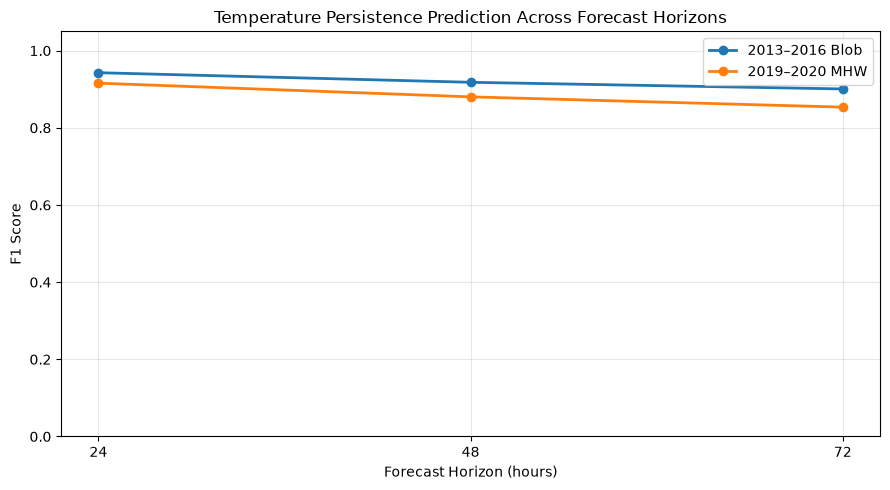

In [18]:
# plot temperature-persistence F1 by forecast horizon

fig, ax = plt.subplots(figsize=(9, 5))

for event, group in horizon_results.groupby("Event"):
    group = group.sort_values("Hours")

    ax.plot(
        group["Hours"],
        group["F1"],
        marker="o",
        linewidth=2,
        label=event
    )

ax.set_title("Temperature Persistence Prediction Across Forecast Horizons")
ax.set_xlabel("Forecast Horizon (hours)")
ax.set_ylabel("F1 Score")
ax.set_xticks([24, 48, 72])
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(OUT / 'Figure_2_5_temperature_persistence_F1.png',dpi=220,bbox_inches='tight')
plt.show()